In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Chargement des 3 fichiers
features = pd.read_csv("../data/raw/elliptic_txs_features.csv", header=None)
edges    = pd.read_csv("../data/raw/elliptic_txs_edgelist.csv")
classes  = pd.read_csv("../data/raw/elliptic_txs_classes.csv")

# On renomme les colonnes pour s'y retrouver
features.columns = ["txId", "time_step"] + [f"f{i}" for i in range(1, 166)]

print("Features :", features.shape)
print("Edges    :", edges.shape)
print("Classes  :", classes.shape)

Features : (203769, 167)
Edges    : (234355, 2)
Classes  : (203769, 2)


In [2]:
print("=== FEATURES (5 premières lignes) ===")
display(features.head())

print("\n=== EDGES (5 premières arêtes) ===")
display(edges.head())

print("\n=== CLASSES (5 premières classes) ===")
display(classes.head())

=== FEATURES (5 premières lignes) ===


,txId,time_step,f1,f2,f3,f4,f5,f6,f7,f8,...,f156,f157,f158,f159,f160,f161,f162,f163,f164,f165
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117



=== EDGES (5 premières arêtes) ===


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206



=== CLASSES (5 premières classes) ===


,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


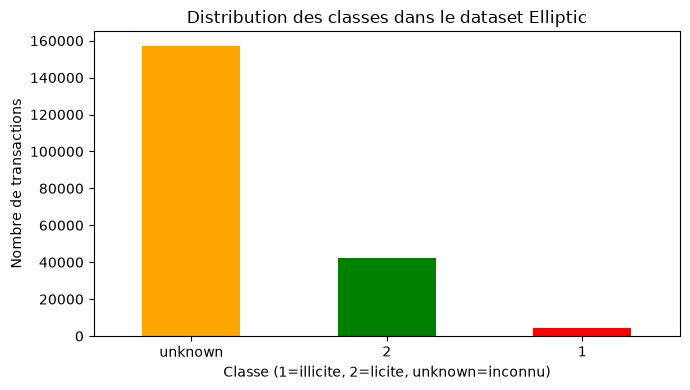

In [3]:
# Distribution des 3 classes
class_counts = classes["class"].value_counts()
print(class_counts)

# Graphique
plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar", color=["orange", "green", "red"])
plt.title("Distribution des classes dans le dataset Elliptic")
plt.xlabel("Classe (1=illicite, 2=licite, unknown=inconnu)")
plt.ylabel("Nombre de transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Min transactions dans un time step : 1089
Max transactions dans un time step : 7880
Nombre total de time steps         : 49


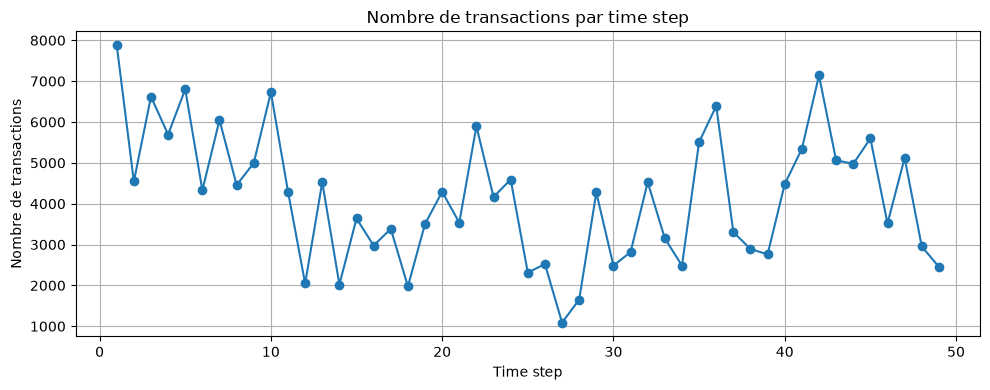

In [4]:
# Combien de transactions par time step ?
transactions_per_ts = features.groupby("time_step").size()

print("Min transactions dans un time step :", transactions_per_ts.min())
print("Max transactions dans un time step :", transactions_per_ts.max())
print("Nombre total de time steps         :", features["time_step"].nunique())

plt.figure(figsize=(10, 4))
transactions_per_ts.plot(kind="line", marker="o")
plt.title("Nombre de transactions par time step")
plt.xlabel("Time step")
plt.ylabel("Nombre de transactions")
plt.grid(True)
plt.tight_layout()
plt.show()

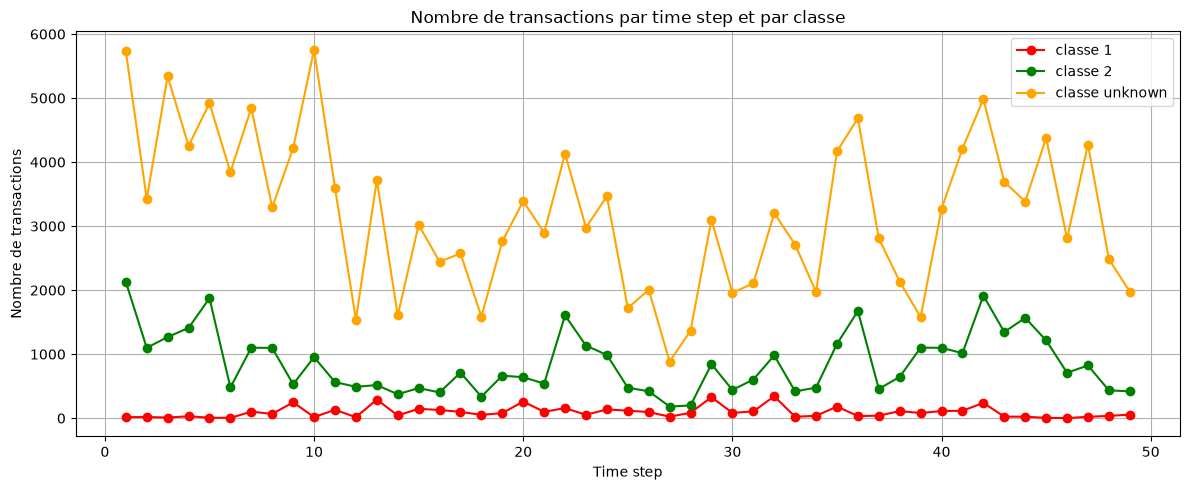

In [5]:
# On joint les features et les classes pour avoir time_step + class
df_merged = features[["txId", "time_step"]].merge(classes, on="txId", how="left")

# Comptage par time step et par classe
ts_class = df_merged.groupby(["time_step", "class"]).size().unstack(fill_value=0)

plt.figure(figsize=(12, 5))
for cls, color in zip(["1", "2", "unknown"], ["red", "green", "orange"]):
    if cls in ts_class.columns:
        plt.plot(ts_class.index, ts_class[cls], label=f"classe {cls}", color=color, marker="o")

plt.title("Nombre de transactions par time step et par classe")
plt.xlabel("Time step")
plt.ylabel("Nombre de transactions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Construire le graphe avec networkx (rapide, en mémoire)
G = nx.from_pandas_edgelist(edges, source="txId1", target="txId2", create_using=nx.DiGraph())

print("Nombre de nœuds  :", G.number_of_nodes())
print("Nombre d'arêtes :", G.number_of_edges())

# Combien de nœuds sont isolés (sans aucune arête) ?
nodes_in_graph = set(G.nodes())
nodes_in_features = set(features["txId"])
nodes_isolated = nodes_in_features - nodes_in_graph
print("Nœuds sans aucune arête :", len(nodes_isolated))

Nombre de nœuds  : 203769
Nombre d'arêtes : 234355
Nœuds sans aucune arête : 0


## 📝 5 observations sur le dataset Elliptic

1. **Déséquilibre extrême.** Il y a **4545** transactions illicites, **42019** licites et **157205** inconnues.
   → Conséquence : on ne peut pas utiliser l'accuracy. On utilisera F1-score et rappel sur les illicites.

2. **Time steps.** Le dataset contient **49** time steps, avec entre **1089** et **7880** transactions par step.
   → Conséquence : on peut faire un split temporel (entraîner sur les premiers, tester sur les derniers).

3. **Graphe.** Le graphe a **203769** nœuds et **234355** arêtes.
   → Conséquence : taille raisonnable pour un GCN sur CPU.

4. **Nœuds isolés.** **0** transactions n'ont aucune arête.
   → Conséquence : tous les nœuds peuvent bénéficier du voisinage du GCN.

5. **Évolution temporelle.** Les illicites sont répartis sur **tous** les time steps (présents à chaque période).
   → Conséquence : le modèle doit apprendre sur tous les time steps pour ne pas être biaisé.